# Lab 2 - Linear models

Let's try to model income from other variables in the [General Social Studies dataset](https://gss.norc.org/get-the-data.html).

We will try to predict CONINC --- its in units of inflation adjusted 2000 dollars so you should be able to compare across survey years.  We will use the following independent variables
1. EDUC is a pretty good predictor of income levels (known from many studies)
2. AGE is too, but see problems below
3. Whatever else you want to add... maybe sex, race, hispanic status, etc.  Whatever you're interested in!
   
Problems to think about 
- Any categorical variables need to be coded as such: For categoricals like gss['HISPANIC'] models of the form "y ~ C(HISPANIC)" are correct, but "y ~ HISPANIC" is WRONG.
- AGE has a clear quadratic nature to it, with peak earnings at about 50 years.  I'll show you how to deal with it for good predictions.
- CONINC is very right skew, logging it makes it somewhat left skew
- If you decide to predict raw CONINC youve probably got some skedasticity problems.  If you predict log transform CONINC thesse problems get better but don't go away.  And now your effect sizes are harder to interpret because they are working on log data.
- CONINC is madeup /inferred from categorical responses; its got problems on both ends of the income scale
    -  see the following report for a better understanding  https://gss.norc.org/content/dam/gss/get-documentation/pdf/reports/methodological-reports/MR101%20Getting%20the%20Most%20Out%20of%20the%20GSS%20Income%20Measures.pdf


What you need to turn in 
1. An EDA of variables (both dependent and independent) that you are interested in including in the model
2. At least five models, investigating various forms of predicting CONIC with model forms of your choice.  All models have to be in your notebook, along with any visualizations you do for those.
3. Pick the best model according to some criteria you choose.
4. Write a report (probably 3 - 6 paragraphs) including
   - how you selected this model over all the others you tried
   - a description of the model and the RATIONALE for the model form... e.g. "log transforming variable X1 produced better adjusted R^2 and less heteroscedasticity than using X1 untransformed", or "In (Smith, 1999) it was shown that income is sex dependent; therefore it was included in this model"
   - interpretation of p-values and effect sizes in your best model, and what that means for understanding the potential causal relationships
   - interpretation of what didn't work in some models you tried... e.g., is there any evidence in the models you explored that including X5 but not X2 is important because it X5 is a confound of X2 and the dependent variable?


**NB1** Feel free to use any of my code below... delete whatever you don't find useful!

**NB2** You probably already have the data locally, but reminder SAS is my recommended download format and the whole GSS dataset is > 2GB unzipped.  If you're space limited or RAM limited maybe only download/use part of it.  ALSO read the documentation about each variable you wish to use!!!

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf

import numpy as np
import scipy.stats as stats

# change the below to work for you!!!  this is my path
gss = pd.read_sas('/Users/jasonfleischer/Documents/Code_local/Data vist css 211/GSS_sas/gss7224_r3a.sas7bdat')


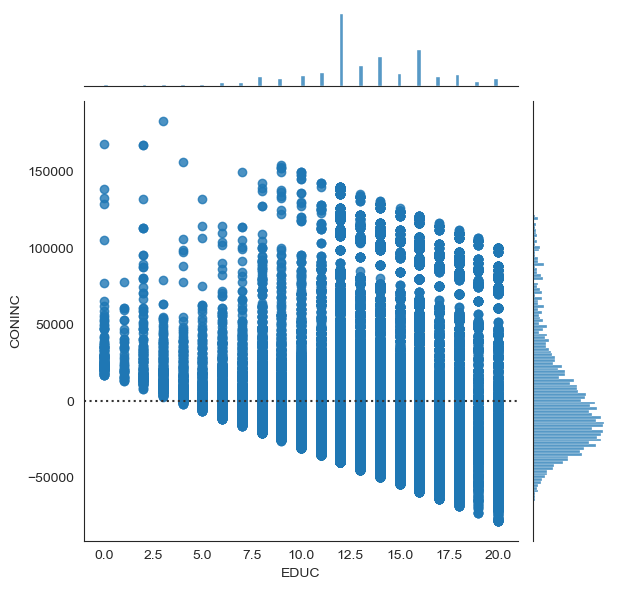

In [67]:
sns.jointplot(data=gss, x='EDUC', y='CONINC', kind='resid');

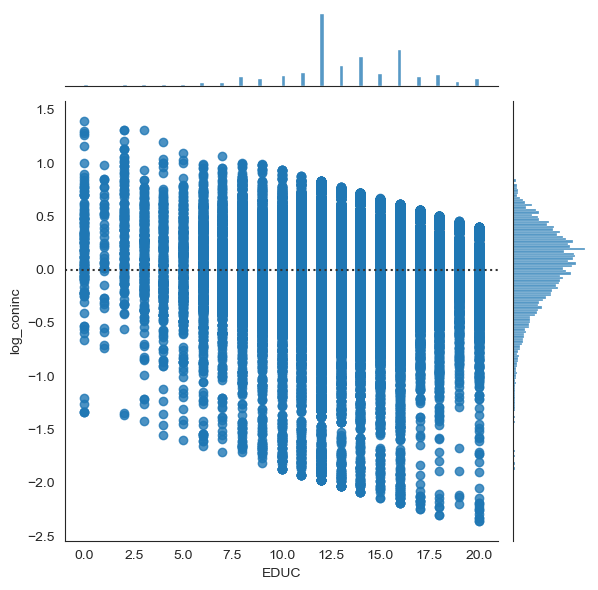

In [68]:
# this might be better to predict because the huge right skew is gone... but its certainly not perfect
gss['log_coninc']=np.log10(gss['CONINC'])
sns.jointplot(data=gss, x='EDUC', y='log_coninc', kind='resid');

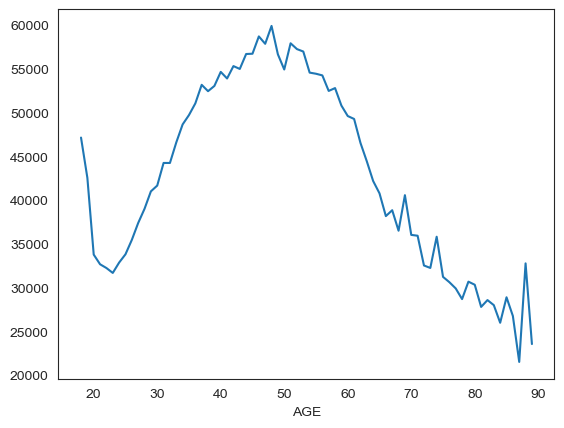

In [69]:
# this would NOT produce a good linear model
gss.groupby('AGE')['CONINC'].mean().plot();

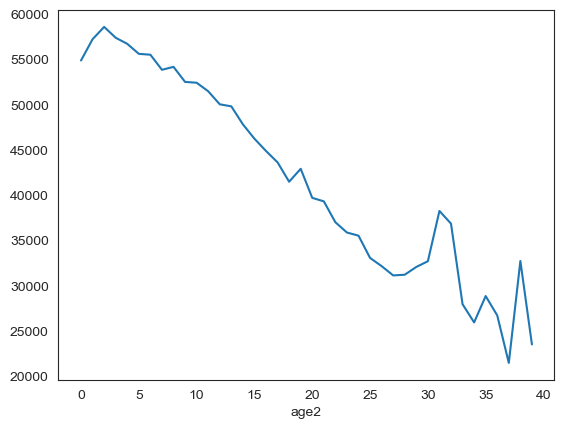

In [83]:
# this would probably be fine to model linearly... I'm taking how far away a person's age is from the peak earning of 50 years
# and yes I tried a real quadratic and for some reason it didn't work as well as absolute value :)
gss['age2']=np.abs(gss['AGE']-50)
gss.groupby('age2')['CONINC'].mean().plot();

In [84]:
m1 = smf.ols(formula='CONINC ~ age2 + EDUC', data=gss)
r1 = m1.fit()
print(r1.summary())


                            OLS Regression Results                            
Dep. Variable:                 CONINC   R-squared:                       0.199
Model:                            OLS   Adj. R-squared:                  0.199
Method:                 Least Squares   F-statistic:                     8339.
Date:                Sat, 10 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:33:45   Log-Likelihood:            -7.9721e+05
No. Observations:               67294   AIC:                         1.594e+06
Df Residuals:                   67291   BIC:                         1.594e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1317.3079    618.964     -2.128      0.0